# CricShield: Component 3 training notebook
### Multimodal XGBoost–LSTM injury-risk classifier with two-level SHAP and narrative explanations

**Pipeline (as in the proposal, Fig. 4.2)**

```
kinematic sequences (Component 2)  ──►  LSTM concept encoder  ──►  named intermediate features ─┐
                                                                  (peak SCR, side-bend slope…)  ├─► XGBoost ─► calibrated risk 0–100 %
workload log + athlete metadata    ──►  workload / profile features ────────────────────────────┘        │
                                                                                                          ▼
                                                     two-level SHAP (modality ▸ feature) ─► narrative + JSON for Component 4
```

**Evaluation protocol**
* Development set (train + val bowlers): **5-fold cross-validation grouped by bowler**, used to compare the hybrid against Baselines 1–3.
* **Held-out test set** (29 bowlers): touched once at the end, reported with bowler-level bootstrap 95 % CIs.
* Imbalance handled with **SMOTE inside each training fold**, compared against class weighting; the hybrid variant with the better CV AUC is kept. The decision threshold is chosen on validation data so that **recall ≥ 0.80**.

> ⚠️ **Synthetic data.** This notebook runs on `cricshield_synthetic_v1`. Results show that the pipeline works; they are **not** evidence about real bowlers. Replace the data loading cell with real Component 1/2 outputs later; nothing else needs to change.

**Before you run:** in Colab choose *Runtime ▸ Change runtime type ▸ T4 GPU*, then *Runtime ▸ Run all*. A full run takes about 15–25 min on a T4 GPU.

## 0. Setup

In [1]:
# Colab already has TensorFlow, XGBoost, scikit-learn and matplotlib. These two may be missing.
import importlib.util, subprocess, sys
for pkg, mod in [("shap", "shap"), ("imbalanced-learn", "imblearn")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
import os, json, time, math, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
import xgboost as xgb
import shap
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, brier_score_loss, roc_curve, confusion_matrix, r2_score,
                             mean_absolute_error)
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

# ------------------------------- configuration -------------------------------
SEED = 2026
QUICK = os.environ.get("CRICSHIELD_QUICK", "0") == "1"   # True = fast smoke test (fewer folds/epochs)
N_FOLDS = 2 if QUICK else 5
CONCEPT_EPOCHS = 3 if QUICK else 40
SPELL_LSTM_EPOCHS = 3 if QUICK else 40
TARGET_RECALL = 0.80          # recall-weighted operating point (proposal Table 5)
HORIZON_DAYS = 28
N_BOOT = 200 if QUICK else 2000

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| XGBoost", xgb.__version__, "| SHAP", shap.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU only: expect a slower run)")
print("QUICK mode" if QUICK else f"Full run: {N_FOLDS}-fold CV")

I0000 00:00:1792257470.625012   13649 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792257471.847221   13649 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | XGBoost 3.4.1 | SHAP 0.54.1
GPU: none (CPU only: expect a slower run)
Full run: 5-fold CV


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ---------------------------- locate / unpack the data ----------------------------
# Option A: upload cricshield_synthetic_v1.zip with the Colab file panel (left sidebar ▸ folder icon).
# Option B: put it in Google Drive at  MyDrive/CricShield/cricshield_synthetic_v1.zip  (outputs are then saved to Drive too).
ZIP_NAME = "cricshield_synthetic_v1.zip"
DRIVE_FOLDER = "/content/drive/MyDrive/CricShield"
IN_COLAB = "google.colab" in sys.modules

def find_data_dir():
    for d in [os.environ.get("CRICSHIELD_DATA", ""), "/content/cricshield_synthetic_v1/data",
              "./cricshield_synthetic_v1/data", "./data"]:
        if d and os.path.exists(os.path.join(d, "model_table_spell_level.csv")):
            return d
    return None

DATA_DIR, OUT_ROOT = find_data_dir(), "./outputs"
if DATA_DIR is None:
    zips = [p for p in [f"/content/{ZIP_NAME}", f"./{ZIP_NAME}"] if os.path.exists(p)]
    if not zips and IN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
        if os.path.exists(f"{DRIVE_FOLDER}/{ZIP_NAME}"):
            zips = [f"{DRIVE_FOLDER}/{ZIP_NAME}"]
            OUT_ROOT = f"{DRIVE_FOLDER}/outputs"
        else:
            from google.colab import files
            print(f"Not found in Drive. Please upload {ZIP_NAME}:")
            up = files.upload()
            zips = [f"/content/{k}" for k in up if k.endswith(".zip")]
    if not zips:
        raise FileNotFoundError(f"Could not find {ZIP_NAME} or an extracted data folder.")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall("/content" if IN_COLAB else ".")
    DATA_DIR = find_data_dir()
elif IN_COLAB and os.path.exists(DRIVE_FOLDER):
    OUT_ROOT = f"{DRIVE_FOLDER}/outputs"

OUT = {k: os.path.join(OUT_ROOT, k) for k in ["models", "figures", "results", "examples"]}
for p in OUT.values():
    os.makedirs(p, exist_ok=True)
print("data   :", os.path.abspath(DATA_DIR))
print("outputs:", os.path.abspath(OUT_ROOT))

data   : /home/claude/cricshield_synth/data
outputs: /home/claude/cricshield_nb/outputs


In [4]:
# ------------------------------- chart style -------------------------------
# Validated categorical order (colour-blind safe on adjacent pairs). Colour follows the entity everywhere.
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", violet="#6250d6",
         ink="#0b0b0b", ink2="#52514e", muted="#8a8984", grid="#e6e5e1", surface="#fcfcfb",
         good="#0ca30c", warning="#fab219", critical="#d03b3b", neg="#2a78d6", pos="#e34948")
MOD_COLOR = {"Technique": C["blue"], "Workload": C["orange"], "Athlete": C["aqua"]}
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "text.color": C["ink"], "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": C["grid"],
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "lines.linewidth": 2,
})
def savefig(fig, name):
    fig.savefig(os.path.join(OUT["figures"], name))

## 1. Load the data
`kinematic_sequences.npz` holds the per-frame joint angles that Component 2 would produce (deliveries × 60 frames × 10 channels at 120 fps). `deliveries.csv` gives the event frames and Component 2's per-delivery metrics, which become the **concept targets** for the LSTM bridge.

In [5]:
athletes = pd.read_csv(f"{DATA_DIR}/athletes.csv")
workload = pd.read_csv(f"{DATA_DIR}/workload_daily.csv")
injuries = pd.read_csv(f"{DATA_DIR}/injuries.csv")
deliv    = pd.read_csv(f"{DATA_DIR}/deliveries.csv")
table    = pd.read_csv(f"{DATA_DIR}/model_table_spell_level.csv")
truth    = pd.read_csv(f"{DATA_DIR}/ground_truth_spells.csv")      # validation only, never a feature
npz      = np.load(f"{DATA_DIR}/kinematic_sequences.npz")
X_raw    = npz["X"].astype("float32")
CHANNELS = [str(c) for c in npz["channels"]]
FPS      = int(npz["fps"])
assert (deliv.delivery_id.values == npz["delivery_id"]).all()

# Every spell has exactly 12 deliveries -> index matrix (n_spells, 12) into X_raw / deliv
deliv_sorted = deliv.sort_values(["spell_id", "delivery_no"])
SPELL_IDS = deliv_sorted.spell_id.values[::12]
D_IDX = deliv_sorted.index.values.reshape(-1, 12)
spells = table.set_index("spell_id").loc[SPELL_IDS].reset_index()
y_all = spells.injury_28d.values.astype(int)
N_SP, N_DEL, T, N_CH = len(spells), D_IDX.shape[1], X_raw.shape[1], X_raw.shape[2]

print(f"{athletes.shape[0]} bowlers | {N_SP} screening spells | {len(deliv)} deliveries | sequences {X_raw.shape}")
print(f"positives: {y_all.sum()} spells ({y_all.mean():.1%}) from {injuries.shape[0]} injuries")
print(spells.groupby("split").agg(spells=("spell_id", "size"), bowlers=("bowler_id", "nunique"),
                                  positive_rate=("injury_28d", "mean")).round(3))

200 bowlers | 2544 screening spells | 30528 deliveries | sequences (30528, 60, 10)
positives: 203 spells (8.0%) from 118 injuries
       spells  bowlers  positive_rate
split                                
test      366       29          0.074
train    1796      139          0.084
val       382       29          0.065


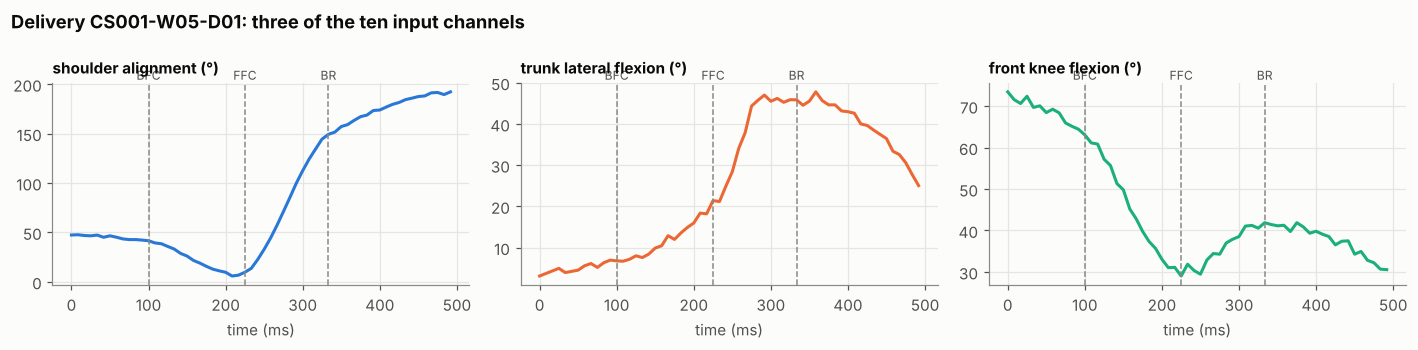

In [6]:
# Look at one delivery: the curves the LSTM will read
d0 = 0
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
t_ms = np.arange(T) / FPS * 1000
for ax, ch, col in zip(axes, [0, 3, 5], [C["blue"], C["orange"], C["aqua"]]):
    ax.plot(t_ms, X_raw[d0, :, ch], color=col)
    for ev, lab in [("bfc_frame", "BFC"), ("ffc_frame", "FFC"), ("br_frame", "BR")]:
        f = deliv.loc[d0, ev] / FPS * 1000
        ax.axvline(f, color=C["muted"], lw=1, ls="--"); ax.text(f, ax.get_ylim()[1], lab, color=C["ink2"], fontsize=8, ha="center", va="bottom")
    ax.set_title(CHANNELS[ch].replace("_deg", " (°)").replace("_", " "), fontsize=10)
    ax.set_xlabel("time (ms)")
fig.suptitle(f"Delivery {deliv.delivery_id[d0]}: three of the ten input channels", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "01_example_delivery.png"); plt.show()

## 2. Feature engineering
### 2a. Kinematic inputs and concept targets
The LSTM receives the 10 angle channels plus 4 one-hot event channels (BFC, FFC, UAH, BR) supplied by Component 2.
It is trained to output **8 named biomechanical concepts per delivery**. This is the *interpretable intermediate-feature bridge*: SHAP later attributes risk to these names instead of to unreadable embedding dimensions.

In [7]:
# Event channels (one-hot at Component 2's event frames)
EVENTS = ["bfc_frame", "ffc_frame", "uah_frame", "br_frame"]
ev_ch = np.zeros((len(deliv), T, len(EVENTS)), dtype="float32")
for j, e in enumerate(EVENTS):
    ev_ch[np.arange(len(deliv)), deliv[e].clip(0, T - 1).values, j] = 1.0
X_in = np.concatenate([X_raw, ev_ch], axis=-1)           # (N, 60, 14)
N_IN = X_in.shape[-1]

# Concept 8: frames from front-foot contact to peak trunk side-bend ("frame index of maximum deviation")
from scipy.signal import savgol_filter
lf = savgol_filter(X_raw[:, :, CHANNELS.index("trunk_lateral_flexion_deg")], 9, 3, axis=1)
win = np.arange(T)[None, :]
mask = (win >= deliv.ffc_frame.values[:, None]) & (win <= np.minimum(deliv.br_frame.values + 8, T - 1)[:, None])
deliv["latflex_peak_timing_frames"] = np.where(mask, lf, -np.inf).argmax(1) - deliv.ffc_frame.values

CONCEPTS = {   # concept name -> Component 2 metric used as the training target
    "scr":            "shoulder_counter_rotation_deg",
    "latflex_peak":   "peak_lateral_flexion_deg",
    "latflex_vel":    "peak_lat_flex_velocity_dps",
    "hss":            "peak_hip_shoulder_sep_deg",
    "trunk_ext":      "trunk_extension_ffc_deg",
    "knee_ffc":       "front_knee_flexion_ffc_deg",
    "elbow_ext":      "elbow_extension_deg",
    "latflex_timing": "latflex_peak_timing_frames",
}
Y_concept = deliv[list(CONCEPTS.values())].values.astype("float32")
print("input tensor", X_in.shape, "| concept targets", Y_concept.shape)
print(deliv[list(CONCEPTS.values())].describe().T[["mean", "std", "min", "max"]].round(2))

input tensor (30528, 60, 14) | concept targets (30528, 8)
                                 mean     std     min     max
shoulder_counter_rotation_deg   28.26   11.79    0.05   65.08
peak_lateral_flexion_deg        38.67    7.07   16.10   67.96
peak_lat_flex_velocity_dps     401.00  113.60  140.31  996.40
peak_hip_shoulder_sep_deg       27.10    7.31    7.48   50.82
trunk_extension_ffc_deg         12.07    5.45   -2.97   33.68
front_knee_flexion_ffc_deg      27.90   10.65   -1.47   69.49
elbow_extension_deg              7.75    3.45   -1.49   23.75
latflex_peak_timing_frames      12.48    2.77    6.00   21.00


### 2b. Workload features, computed from the raw daily log
This is the same calculation Component 3 will run on real coach-entered logs.

In [8]:
def workload_features(log: pd.DataFrame) -> pd.DataFrame:
    w = log.sort_values(["bowler_id", "day"]).copy()
    active = w.session_type != "rest"
    for col in ["srpe", "duration_min"]:                      # impute missing entries per bowler x session type
        med = w.groupby(["bowler_id", "session_type"])[col].transform("median")
        w[col] = np.where(active, w[col].fillna(med), np.nan)
    w["session_load"] = (w.srpe * w.duration_min).fillna(0)
    w["bowled"] = (w.deliveries > 0).astype(int)
    out = []
    for _, g in w.groupby("bowler_id", sort=False):
        g = g.copy(); d = g.deliveries; sl = g.session_load
        g["deliveries_7d"] = d.rolling(7, min_periods=1).sum()
        g["deliveries_28d_weekly"] = d.rolling(28, min_periods=7).sum() / (d.rolling(28, min_periods=7).count() / 7)
        g["acwr_7_28"] = g.deliveries_7d / g.deliveries_28d_weekly.replace(0, np.nan)
        g["ewma_ratio"] = d.ewm(alpha=2/8, adjust=False).mean() / d.ewm(alpha=2/29, adjust=False).mean().replace(0, np.nan)
        g["differential_load_7d"] = (g.deliveries_7d - g.deliveries_7d.shift(7).fillna(0)).ewm(alpha=2/8, adjust=False).mean()
        g["session_load_7d"] = sl.rolling(7, min_periods=1).sum()
        g["monotony_7d"] = sl.rolling(7, min_periods=2).mean() / sl.rolling(7, min_periods=2).std().replace(0, np.nan)
        g["strain_7d"] = g.session_load_7d * g.monotony_7d
        g["bowling_days_7d"] = g.bowled.rolling(7, min_periods=1).sum()
        g["matches_14d"] = (g.session_type == "match").astype(int).rolling(14, min_periods=1).sum()
        g["max_daily_deliveries_7d"] = d.rolling(7, min_periods=1).max()
        g["rest_days_7d"] = (g.session_type == "rest").astype(int).rolling(7, min_periods=1).sum()
        g["consecutive_bowling_days"] = g.bowled.groupby((g.bowled == 0).cumsum()).cumsum()
        out.append(g)
    return pd.concat(out)

WORK_FEATS = ["deliveries_7d", "deliveries_28d_weekly", "acwr_7_28", "ewma_ratio", "differential_load_7d",
              "session_load_7d", "monotony_7d", "strain_7d", "bowling_days_7d", "matches_14d",
              "max_daily_deliveries_7d", "rest_days_7d", "consecutive_bowling_days"]
wf = workload_features(workload)
spell_day = pd.read_csv(f"{DATA_DIR}/spells.csv").set_index("spell_id").loc[SPELL_IDS, ["day"]].reset_index()
spell_day["bowler_id"] = spells.bowler_id.values
W = spell_day.merge(wf[["bowler_id", "day"] + WORK_FEATS], on=["bowler_id", "day"], how="left")[WORK_FEATS]
W.index = spells.index
# Check against the dataset's pre-computed columns. Ball-count features match exactly; sRPE-based ones differ
# slightly because the raw log has missing sRPE/duration entries that we impute here.
print("max |difference| vs pre-computed:", (W - spells[WORK_FEATS]).abs().max().round(3).to_dict())
W.describe().T[["mean", "std", "min", "max"]].round(2)

max |difference| vs pre-computed: {'deliveries_7d': 0.0, 'deliveries_28d_weekly': 0.0, 'acwr_7_28': 0.0, 'ewma_ratio': 0.0, 'differential_load_7d': 0.0, 'session_load_7d': 888.0, 'monotony_7d': 0.513, 'strain_7d': 976.314, 'bowling_days_7d': 0.0, 'matches_14d': 0.0, 'max_daily_deliveries_7d': 0.0, 'rest_days_7d': 0.0, 'consecutive_bowling_days': 0.0}


,mean,std,min,max
deliveries_7d,124.15,49.25,13.00,351.00
deliveries_28d_weekly,116.33,41.96,4.50,255.50
acwr_7_28,1.14,0.48,0.20,4.00
ewma_ratio,1.18,0.26,0.56,3.52
differential_load_7d,4.17,31.44,-131.76,139.18
session_load_7d,2818.03,885.29,292.00,5654.00
monotony_7d,0.98,0.26,0.38,3.07
strain_7d,2745.48,1060.41,110.37,8870.06
bowling_days_7d,3.61,0.92,1.00,6.00
matches_14d,1.57,0.92,0.00,5.00


### 2c. Athlete metadata
`height_cm`, `mass_kg` and `bmi` are **left out on purpose**. They are fixed per bowler, so in a cohort of about 200 the trees use them to *recognise individual bowlers* instead of learning risk (in testing, height became the #1 SHAP feature despite having no effect). Missing values have a meaning here, so they are filled by rule rather than by median.

In [9]:
META_NUM = ["age_at_screen", "maturity_offset_yrs", "typical_pace_kmh", "years_bowling", "prior_lumbar_12m",
            "prior_hamstring_12m", "prior_side_strain_12m", "prior_injury_count_12m", "months_since_last_injury",
            "in_season_injuries_before", "days_since_rtp"]
META_CAT = {"level": ["school", "club", "academy"], "bowling_role": ["opening", "change"],
            "action_type_coach": ["side-on", "front-on", "semi-open", "mixed"], "bowling_arm": ["R", "L"]}
M = spells.merge(athletes[["bowler_id", "typical_pace_kmh"]], on="bowler_id", how="left")[META_NUM].copy()
M["maturity_offset_yrs"] = M.maturity_offset_yrs.fillna(5.0)        # blank = adult -> fully mature
M["months_since_last_injury"] = M.months_since_last_injury.fillna(24.0)  # blank = no injury in 12 months
M["days_since_rtp"] = M.days_since_rtp.fillna(365.0)                 # blank = no in-season injury
for col, cats in META_CAT.items():
    for c in cats:
        M[f"{col}_{c}"] = (spells[col] == c).astype(float)
M.index = spells.index
META_FEATS = list(M.columns)

# Component 2's hand-crafted kinematic summaries (used only for the ablation model)
C2_FEATS = ["scr_mean", "scr_peak", "scr_slope_per_delivery", "n_deliveries_scr_over_30", "latflex_mean", "latflex_peak",
            "latflex_slope_per_delivery", "latflex_max_delivery_no", "latflex_vel_mean", "hss_mean",
            "trunk_ext_ffc_mean", "knee_flex_ffc_mean", "elbow_ext_mean"]
K2 = spells[C2_FEATS].copy()
print(f"{len(WORK_FEATS)} workload features | {len(META_FEATS)} metadata features | {len(C2_FEATS)} Component-2 kinematic summaries")

13 workload features | 22 metadata features | 13 Component-2 kinematic summaries


## 3. Models
| Name | What it is | Inputs |
|---|---|---|
| **B1** | Logistic regression (class-weighted) | workload + metadata |
| **B2** | XGBoost + SMOTE | workload + metadata |
| **B3** | Standalone LSTM (end-to-end) | raw kinematic sequences of the 12-ball spell |
| **H** | **Hybrid**: LSTM concept encoder ▸ named features ▸ XGBoost + SMOTE | kinematics + workload + metadata |
| H-w | Hybrid with class weights instead of SMOTE | same as H |
| A | Ablation: Component 2's hand-crafted summaries instead of the LSTM bridge | same as H |

All models share the same inner validation bowlers, which are used for **early stopping, Platt calibration (0–100 % score) and the recall ≥ 0.80 threshold**.

In [10]:
# ------------------------------ helpers ------------------------------
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def sigmoid(z): return 1 / (1 + np.exp(-z))

PLATT_FALLBACKS = []
class Platt:
    # maps a model's raw margin (log-odds) to a calibrated probability: p = sigmoid(a * margin + b).
    # The slope must stay positive: on a small validation set a noisy fit can come out flat or negative,
    # which would REVERSE the model's ranking (AUC < 0.5). In that case keep the ranking and only shift it.
    def fit(self, margin, y):
        lr = LogisticRegression(C=100.0, max_iter=1000).fit(margin.reshape(-1, 1), y)
        a, b = float(lr.coef_[0, 0]), float(lr.intercept_[0])
        self.fallback = a < 0.05
        if self.fallback:
            a, b = 1.0, float(logit(np.array([y.mean()]))[0] - np.median(margin))
        PLATT_FALLBACKS.append(self.fallback)
        self.a, self.b = a, b; return self
    def __call__(self, margin): return sigmoid(self.a * margin + self.b)

def recall_threshold(p, y, target=TARGET_RECALL):
    # highest threshold that still catches >= target share of positives
    pos = np.sort(p[y == 1])[::-1]
    return float(pos[max(0, math.ceil(target * len(pos)) - 1)]) if len(pos) else 0.5

def metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    return dict(AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),
                recall=recall_score(y, yhat, zero_division=0), precision=precision_score(y, yhat, zero_division=0),
                F1=f1_score(y, yhat, zero_division=0), brier=brier_score_loss(y, p), flagged=yhat.mean())

def inner_split(sp_idx, seed):
    # bowler-level 85/15 split of training spells, stratified by "bowler ever injured"
    b = spells.iloc[sp_idx].groupby("bowler_id").injury_28d.max()
    rng = np.random.default_rng(seed); val_b = []
    for _, grp in b.groupby(b):
        ids = rng.permutation(grp.index.values); val_b += list(ids[:max(1, round(0.15 * len(ids)))])
    is_val = spells.bowler_id.iloc[sp_idx].isin(val_b).values
    return sp_idx[~is_val], sp_idx[is_val]

XGB_PARAMS = dict(n_estimators=250, max_depth=2, learning_rate=0.03, subsample=0.7, colsample_bytree=0.6,
                  min_child_weight=25, reg_lambda=10.0, gamma=1.0, eval_metric="logloss", n_jobs=-1)

def fit_xgb(Xtr, ytr, balance="smote", seed=SEED):
    med = Xtr.median()
    Xtr = Xtr.fillna(med)
    if balance == "smote":
        Xs, ys = SMOTE(sampling_strategy=0.5, k_neighbors=5, random_state=seed).fit_resample(Xtr, ytr)
        m = xgb.XGBClassifier(**XGB_PARAMS, random_state=seed).fit(Xs, ys)
    else:
        m = xgb.XGBClassifier(**XGB_PARAMS, scale_pos_weight=(ytr == 0).sum() / max(1, ytr.sum()), random_state=seed).fit(Xtr, ytr)
    m.fill_values_ = med
    return m

def xgb_margin(m, X): return m.predict(X.fillna(m.fill_values_), output_margin=True)

### 3a. LSTM concept encoder (the bridge)
A 2-layer bidirectional LSTM reads one delivery (60 frames × 14 channels). Its final hidden state is the learned kinematic embedding, which a small head turns into the 8 named concepts. Huber loss keeps the model robust to tracking glitches.

In [11]:
def build_concept_encoder(n_concepts=len(CONCEPTS), units=64):
    inp = keras.Input((T, N_IN), name="delivery_sequence")
    x = layers.Bidirectional(layers.LSTM(units, return_sequences=True))(inp)
    x = layers.Bidirectional(layers.LSTM(units // 2))(x)                 # final hidden state h_T
    emb = layers.Dense(64, activation="relu", name="kinematic_embedding")(x)
    out = layers.Dense(n_concepts, name="named_concepts")(emb)
    m = keras.Model(inp, out, name="concept_encoder")
    m.compile(optimizer=keras.optimizers.Adam(2e-3), loss=keras.losses.Huber(delta=1.0))
    return m

class SeqScaler:
    # per-channel standardisation of the 10 angle channels (event channels stay 0/1)
    def fit(self, X):
        self.mu = X[..., :N_CH].mean((0, 1)); self.sd = X[..., :N_CH].std((0, 1)) + 1e-6; return self
    def __call__(self, X):
        Z = X.copy(); Z[..., :N_CH] = (Z[..., :N_CH] - self.mu) / self.sd; return Z

def train_concept_encoder(tr_sp, va_sp, seed=SEED, verbose=0):
    keras.utils.set_random_seed(seed)
    tr_d, va_d = D_IDX[tr_sp].ravel(), D_IDX[va_sp].ravel()
    sx = SeqScaler().fit(X_in[tr_d])
    ymu, ysd = Y_concept[tr_d].mean(0), Y_concept[tr_d].std(0) + 1e-6
    model = build_concept_encoder()
    hist = model.fit(sx(X_in[tr_d]), (Y_concept[tr_d] - ymu) / ysd,
                     validation_data=(sx(X_in[va_d]), (Y_concept[va_d] - ymu) / ysd),
                     epochs=CONCEPT_EPOCHS, batch_size=256, verbose=verbose,
                     callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                                keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)])
    return dict(model=model, sx=sx, ymu=ymu, ysd=ysd, history=hist.history)

def predict_concepts(enc, d_idx, batch=1024):
    return enc["model"].predict(enc["sx"](X_in[d_idx]), batch_size=batch, verbose=0) * enc["ysd"] + enc["ymu"]

CN = list(CONCEPTS)
def spell_concept_features(Cd):
    # Cd: (n_spells, 12, n_concepts) predicted concepts -> named spell-level features
    n = Cd.shape[0]; x = np.arange(N_DEL) - (N_DEL - 1) / 2
    slope = lambda v: (v * x).sum(1) / (x ** 2).sum()
    g = lambda c: Cd[:, :, CN.index(c)]
    f = {
        "lstm_scr_mean": g("scr").mean(1), "lstm_scr_peak": g("scr").max(1), "lstm_scr_slope": slope(g("scr")),
        "lstm_scr_n_over_30": (g("scr") > 30).sum(1).astype(float),
        "lstm_latflex_mean": g("latflex_peak").mean(1), "lstm_latflex_peak": g("latflex_peak").max(1),
        "lstm_latflex_slope": slope(g("latflex_peak")), "lstm_latflex_max_delivery": g("latflex_peak").argmax(1) + 1.0,
        "lstm_latflex_vel_mean": g("latflex_vel").mean(1), "lstm_hss_mean": g("hss").mean(1),
        "lstm_trunk_ext_mean": g("trunk_ext").mean(1), "lstm_knee_ffc_mean": g("knee_ffc").mean(1),
        "lstm_elbow_ext_mean": g("elbow_ext").mean(1), "lstm_latflex_timing_mean": g("latflex_timing").mean(1),
    }
    return pd.DataFrame(f)
LSTM_FEATS = list(spell_concept_features(np.zeros((1, N_DEL, len(CN)))).columns)
print(build_concept_encoder().count_params(), "parameters in the concept encoder;", len(LSTM_FEATS), "named spell features")

86344 parameters in the concept encoder; 14 named spell features


### 3b. Baseline 3: standalone LSTM classifier
The same LSTM idea trained end to end on injury labels: a delivery-level LSTM is applied to each of the 12 balls, then a spell-level LSTM runs across the balls to capture fatigue drift. It has no named features, so it is accurate or not, but never explainable in coach terms.

In [12]:
def build_spell_lstm(units=32):
    inp = keras.Input((N_DEL, T, N_IN), name="spell_sequences")
    z = layers.TimeDistributed(layers.LSTM(units), name="per_delivery_lstm")(inp)   # (12, units)
    z = layers.LSTM(16, name="across_spell_lstm")(z)
    z = layers.Dropout(0.3)(z)
    out = layers.Dense(1, activation="sigmoid")(z)
    m = keras.Model(inp, out, name="baseline3_lstm")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return m

def fit_predict_spell_lstm(tr_sp, va_sp, ev_sp, sx, seed=SEED):
    keras.utils.set_random_seed(seed)
    S = lambda sp: sx(X_in[D_IDX[sp].ravel()]).reshape(len(sp), N_DEL, T, N_IN)
    ytr = y_all[tr_sp]
    m = build_spell_lstm()
    m.fit(S(tr_sp), ytr, validation_data=(S(va_sp), y_all[va_sp]), epochs=SPELL_LSTM_EPOCHS, batch_size=64, verbose=0,
          class_weight={0: 1.0, 1: float((ytr == 0).sum() / max(1, ytr.sum()))},
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)])
    return logit(m.predict(S(va_sp), verbose=0).ravel()), logit(m.predict(S(ev_sp), verbose=0).ravel()), m

### 3c. One function that trains every model on a set of training bowlers and scores a set of evaluation bowlers

In [13]:
TAB_FEATS = WORK_FEATS + META_FEATS
def tabular(idx): return pd.concat([W.iloc[idx], M.iloc[idx]], axis=1).reset_index(drop=True)

def run_models(train_sp, eval_sp, seed=SEED, models=("B1", "B2", "B3", "H", "H-w", "A"), keep=False):
    tr, va = inner_split(train_sp, seed)
    out, fitted = {}, {}
    def finish(name, m_va, m_ev, obj=None):
        cal = Platt().fit(m_va, y_all[va]); p_va, p_ev = cal(m_va), cal(m_ev)
        out[name] = dict(p=p_ev, thr=recall_threshold(p_va, y_all[va]), cal=cal)
        if keep: fitted[name] = obj

    # --- LSTM concept encoder (bridge) ---
    enc = train_concept_encoder(tr, va, seed)
    Cd = {k: predict_concepts(enc, D_IDX[s].ravel()).reshape(len(s), N_DEL, -1) for k, s in [("tr", tr), ("va", va), ("ev", eval_sp)]}
    Kf = {k: spell_concept_features(v) for k, v in Cd.items()}
    yd_ev = Y_concept[D_IDX[eval_sp].ravel()]
    out["_concept_r2"] = {c: r2_score(yd_ev[:, j], Cd["ev"].reshape(-1, len(CN))[:, j]) for j, c in enumerate(CN)}
    out["_concept_pred_ev"] = Cd["ev"].reshape(-1, len(CN))

    Ttr, Tva, Tev = tabular(tr), tabular(va), tabular(eval_sp)
    if "B1" in models:
        lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=3000, class_weight="balanced"))
        lr.fit(Ttr.fillna(Ttr.median()), y_all[tr]); med = Ttr.median()
        finish("B1", lr.decision_function(Tva.fillna(med)), lr.decision_function(Tev.fillna(med)), (lr, med))
    if "B2" in models:
        m = fit_xgb(Ttr, y_all[tr], "smote", seed); finish("B2", xgb_margin(m, Tva), xgb_margin(m, Tev), m)
    if "B3" in models:
        mva, mev, m = fit_predict_spell_lstm(tr, va, eval_sp, enc["sx"], seed); finish("B3", mva, mev, m)
    Htr, Hva, Hev = [pd.concat([k, t], axis=1) for k, t in [(Kf["tr"], Ttr), (Kf["va"], Tva), (Kf["ev"], Tev)]]
    for name, bal in [("H", "smote"), ("H-w", "weight")]:
        if name in models:
            m = fit_xgb(Htr, y_all[tr], bal, seed); finish(name, xgb_margin(m, Hva), xgb_margin(m, Hev), m)
    if "A" in models:
        A_ = lambda s, t: pd.concat([K2.iloc[s].reset_index(drop=True), t], axis=1)
        m = fit_xgb(A_(tr, Ttr), y_all[tr], "smote", seed); finish("A", xgb_margin(m, A_(va, Tva)), xgb_margin(m, A_(eval_sp, Tev)), m)
    if keep:
        fitted.update(encoder=enc, X_eval=Hev, X_train=Htr, train_sp=tr, val_sp=va)
    return out, fitted

## 4. Cross-validation on the development set (grouped by bowler)
The test bowlers are not used here. Each fold trains every model from scratch, **including the LSTM encoder**, so no evaluation bowler ever influences any part of the pipeline.

In [14]:
dev_sp = np.where(spells.split.isin(["train", "val"]))[0]
test_sp = np.where(spells.split == "test")[0]
MODELS = ["B1", "B2", "B3", "H", "H-w", "A"]
oof = {m: np.full(N_SP, np.nan) for m in MODELS}
fold_rows, r2_rows = [], []
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
t0 = time.time()
for k, (a, b) in enumerate(cv.split(dev_sp.reshape(-1, 1), y_all[dev_sp], spells.bowler_id.values[dev_sp])):
    tr_sp, ev_sp = dev_sp[a], dev_sp[b]
    res, _ = run_models(tr_sp, ev_sp, seed=SEED + k)
    r2_rows.append(res["_concept_r2"])
    for m in MODELS:
        oof[m][ev_sp] = res[m]["p"]
        fold_rows.append(dict(fold=k + 1, model=m, **metrics(y_all[ev_sp], res[m]["p"], res[m]["thr"])))
    print(f"fold {k + 1}/{N_FOLDS}  ({time.time() - t0:.0f}s)  " +
          "  ".join(f"{m}={roc_auc_score(y_all[ev_sp], res[m]['p']):.3f}" for m in MODELS))

print(f"Platt slope fallbacks: {sum(PLATT_FALLBACKS)} of {len(PLATT_FALLBACKS)} calibrations")
cv_folds = pd.DataFrame(fold_rows)
cv_summary = cv_folds.groupby("model").agg(["mean", "std"]).drop(columns="fold").round(3)
cv_summary = cv_summary.loc[MODELS]
cv_folds.to_csv(f"{OUT['results']}/cv_fold_metrics.csv", index=False)
cv_summary.to_csv(f"{OUT['results']}/cv_summary.csv")
print("\nConcept encoder R² on held-out bowlers (mean over folds):")
print(pd.DataFrame(r2_rows).mean().round(3).to_string())
cv_summary[["AUC", "PR_AUC", "recall", "precision", "F1", "brier"]]

fold 1/5  (454s)  B1=0.496  B2=0.468  B3=0.595  H=0.525  H-w=0.612  A=0.491


fold 2/5  (914s)  B1=0.569  B2=0.669  B3=0.436  H=0.720  H-w=0.711  A=0.710


fold 3/5  (1393s)  B1=0.737  B2=0.726  B3=0.697  H=0.763  H-w=0.813  A=0.771


fold 4/5  (1847s)  B1=0.775  B2=0.761  B3=0.845  H=0.792  H-w=0.823  A=0.807


fold 5/5  (2298s)  B1=0.460  B2=0.765  B3=0.550  H=0.743  H-w=0.744  A=0.756
Platt slope fallbacks: 4 of 30 calibrations

Concept encoder R² on held-out bowlers (mean over folds):
scr               0.989
latflex_peak      0.994
latflex_vel       0.935
hss               0.994
trunk_ext         0.992
knee_ffc          0.993
elbow_ext         0.969
latflex_timing    0.610


AUC        PR_AUC        recall        precision            F1         brier       
        mean    std   mean    std   mean    std      mean    std   mean    std   mean    std
model                                                                                       
B1     0.607  0.142  0.266  0.136  0.678  0.187     0.097  0.043  0.166  0.064  0.073  0.003
B2     0.678  0.124  0.213  0.080  0.824  0.150     0.101  0.019  0.180  0.033  0.073  0.005
B3     0.625  0.155  0.185  0.166  0.728  0.255     0.096  0.018  0.168  0.033  0.082  0.010
H      0.708  0.106  0.267  0.110  0.720  0.220     0.126  0.031  0.214  0.054  0.075  0.010
H-w    0.741  0.086  0.293  0.120  0.736  0.357     0.118  0.041  0.198  0.076  0.075  0.013
A      0.707  0.126  0.268  0.117  0.730  0.295     0.124  0.047  0.210  0.079  0.073  0.011

Selected hybrid variant (by CV AUC): Hybrid (class weights)


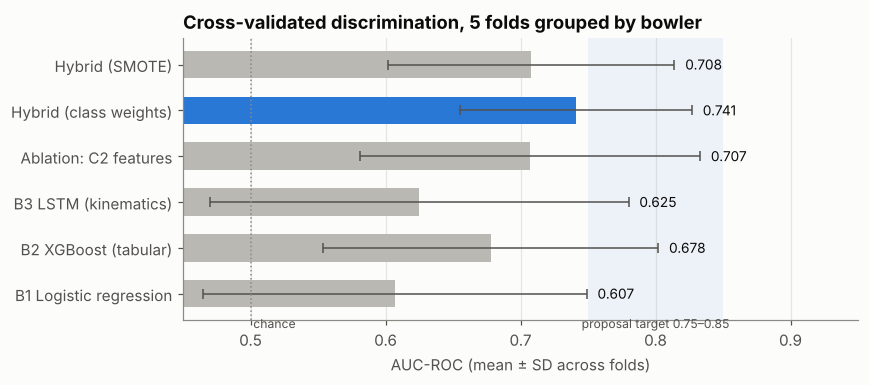

In [15]:
LABEL = {"B1": "B1 Logistic regression", "B2": "B2 XGBoost (tabular)", "B3": "B3 LSTM (kinematics)",
         "H": "Hybrid (SMOTE)", "H-w": "Hybrid (class weights)", "A": "Ablation: C2 features"}
# Model selection on the development set only: keep the hybrid variant with the higher cross-validated AUC.
BEST = max(["H", "H-w"], key=lambda m: cv_summary.loc[m, ("AUC", "mean")])
print(f"Selected hybrid variant (by CV AUC): {LABEL[BEST]}")
order = ["B1", "B2", "B3", "A", "H-w", "H"]
mean, sd = cv_summary["AUC"]["mean"].loc[order], cv_summary["AUC"]["std"].loc[order]
fig, ax = plt.subplots(figsize=(8, 3.6))
cols = [C["blue"] if m == BEST else "#b9b8b2" for m in order]
ax.barh([LABEL[m] for m in order], mean, xerr=sd, color=cols, height=0.6, error_kw=dict(ecolor=C["ink2"], lw=1, capsize=3))
for i, (v, s) in enumerate(zip(mean, sd)):
    ax.text(v + s + 0.008, i, f"{v:.3f}", va="center", color=C["ink"], fontsize=9)
ax.axvline(0.5, color=C["muted"], lw=1, ls=":"); ax.text(0.502, -0.75, "chance", color=C["ink2"], fontsize=8)
ax.axvspan(0.75, 0.85, color=C["blue"], alpha=0.07, lw=0); ax.text(0.80, -0.75, "proposal target 0.75–0.85", color=C["ink2"], fontsize=8, ha="center")
ax.set_xlim(0.45, 0.95); ax.set_xlabel("AUC-ROC (mean ± SD across folds)"); ax.grid(axis="y", visible=False)
ax.set_title(f"Cross-validated discrimination, {N_FOLDS} folds grouped by bowler")
fig.tight_layout(); savefig(fig, "02_cv_auc_comparison.png"); plt.show()

## 5. Final model: train on all development bowlers, evaluate once on the held-out test set
Both hybrid variants are trained so they can be compared below. Sections 6–9 use the variant **selected by cross-validation** (`BEST`).

In [16]:
t0 = time.time()
final, F = run_models(dev_sp, test_sp, seed=SEED, keep=True)
print(f"trained in {time.time() - t0:.0f}s")
y_te = y_all[test_sp]; te_bowlers = spells.bowler_id.values[test_sp]
rng = np.random.default_rng(SEED)
ub = np.unique(te_bowlers); rows_of = {b: np.where(te_bowlers == b)[0] for b in ub}

def boot_ci(m):
    p, thr = final[m]["p"], final[m]["thr"]; vals = []
    for _ in range(N_BOOT):
        idx = np.concatenate([rows_of[b] for b in rng.choice(ub, len(ub))])
        if 0 < y_te[idx].sum() < len(idx): vals.append(metrics(y_te[idx], p[idx], thr))
    v = pd.DataFrame(vals); return v.quantile(0.025), v.quantile(0.975)

rows = []
for m in MODELS:
    pt = metrics(y_te, final[m]["p"], final[m]["thr"]); lo, hi = boot_ci(m)
    rows.append({"model": LABEL[m], **{k: f"{pt[k]:.3f} [{lo[k]:.2f}–{hi[k]:.2f}]" for k in ["AUC", "recall", "precision", "F1"]},
                 "threshold": round(final[m]["thr"], 3)})
test_table = pd.DataFrame(rows).set_index("model")
test_table.to_csv(f"{OUT['results']}/test_metrics_with_95ci.csv")
print(f"Held-out test: {len(test_sp)} spells, {len(ub)} bowlers, {y_te.sum()} positive spells. 95% CI = bowler-level bootstrap.")
test_table

trained in 731s


Held-out test: 366 spells, 29 bowlers, 27 positive spells. 95% CI = bowler-level bootstrap.


,AUC,recall,precision,F1,threshold
model,,,,,
B1 Logistic regression,0.731 [0.52–0.95],0.815 [0.58–1.00],0.084 [0.03–0.15],0.152 [0.06–0.26],0.063
B2 XGBoost (tabular),0.731 [0.53–0.95],0.963 [0.90–1.00],0.094 [0.04–0.18],0.172 [0.07–0.30],0.048
B3 LSTM (kinematics),0.850 [0.66–0.97],0.889 [0.61–1.00],0.131 [0.04–0.25],0.229 [0.08–0.39],0.058
Hybrid (SMOTE),0.846 [0.67–0.96],0.852 [0.52–1.00],0.123 [0.04–0.24],0.215 [0.08–0.38],0.049
Hybrid (class weights),0.909 [0.79–0.98],0.926 [0.76–1.00],0.214 [0.09–0.39],0.347 [0.17–0.56],0.058
Ablation: C2 features,0.854 [0.70–0.96],0.963 [0.87–1.00],0.136 [0.05–0.25],0.239 [0.10–0.40],0.050


Hybrid (class weights) AUC  train (in-sample) 0.950 | CV 0.741 | test 0.909


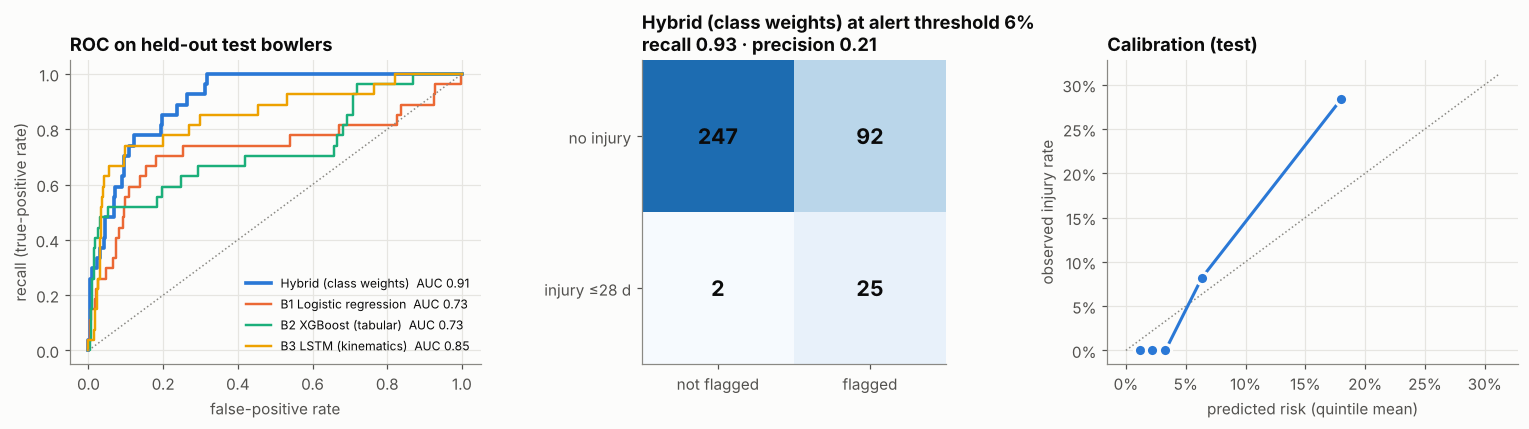

In [17]:
# Overfitting check: AUC on the hybrid's own training spells vs cross-validated and test AUC
train_auc = roc_auc_score(y_all[F["train_sp"]], xgb_margin(F[BEST], F["X_train"]))
print(f"{LABEL[BEST]} AUC  train (in-sample) {train_auc:.3f} | CV {cv_summary.loc[BEST, ('AUC', 'mean')]:.3f} | test {roc_auc_score(y_te, final[BEST]['p']):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
for m, col in [(BEST, C["blue"]), ("B1", C["orange"]), ("B2", C["aqua"]), ("B3", C["yellow"])]:
    fpr, tpr, _ = roc_curve(y_te, final[m]["p"])
    ax.plot(fpr, tpr, color=col, lw=2.4 if m == BEST else 1.6, label=f"{LABEL[m]}  AUC {roc_auc_score(y_te, final[m]['p']):.2f}")
ax.plot([0, 1], [0, 1], color=C["muted"], lw=1, ls=":")
ax.set_xlabel("false-positive rate"); ax.set_ylabel("recall (true-positive rate)"); ax.set_title("ROC on held-out test bowlers")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
p, thr = final[BEST]["p"], final[BEST]["thr"]
cm = confusion_matrix(y_te, (p >= thr).astype(int))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.3); ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v}", ha="center", va="center", fontsize=14, color=C["ink"], fontweight="bold")
ax.set_xticks([0, 1], ["not flagged", "flagged"]); ax.set_yticks([0, 1], ["no injury", "injury ≤28 d"])
ax.set_title(f"{LABEL[BEST]} at alert threshold {thr:.0%}\nrecall {cm[1,1]/cm[1].sum():.2f} · precision {cm[1,1]/max(1,cm[:,1].sum()):.2f}")

ax = axes[2]
bins = np.quantile(p, np.linspace(0, 1, 6)); idx = np.clip(np.digitize(p, bins[1:-1]), 0, 4)
mp = [p[idx == b].mean() for b in range(5)]; ob = [y_te[idx == b].mean() for b in range(5)]
ax.plot([0, max(mp + ob) * 1.1], [0, max(mp + ob) * 1.1], color=C["muted"], lw=1, ls=":")
ax.plot(mp, ob, "o-", color=C["blue"], ms=8, mec=C["surface"], mew=2)
ax.set_xlabel("predicted risk (quintile mean)"); ax.set_ylabel("observed injury rate"); ax.set_title("Calibration (test)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); savefig(fig, "03_test_roc_confusion_calibration.png"); plt.show()

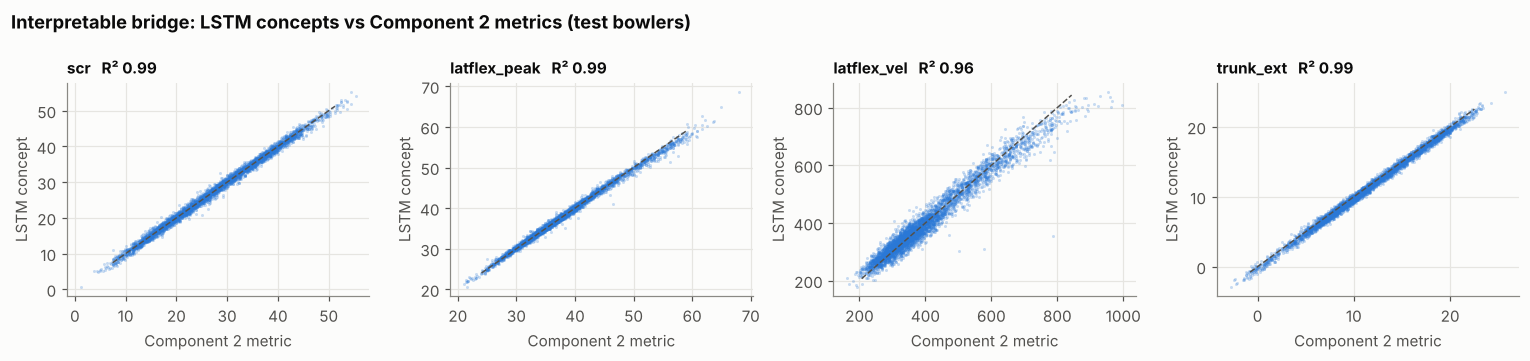

scr               0.994
latflex_peak      0.993
latflex_vel       0.957
hss               0.995
trunk_ext         0.993
knee_ffc          0.997
elbow_ext         0.953
latflex_timing    0.687


In [18]:
# How well does the LSTM bridge reproduce Component 2's metrics on unseen bowlers?
Cp = final["_concept_pred_ev"]; Yt = Y_concept[D_IDX[test_sp].ravel()]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, c in zip(axes, ["scr", "latflex_peak", "latflex_vel", "trunk_ext"]):
    j = CN.index(c)
    ax.scatter(Yt[:, j], Cp[:, j], s=4, alpha=0.25, color=C["blue"], lw=0)
    lim = [np.percentile(Yt[:, j], 0.5), np.percentile(Yt[:, j], 99.5)]
    ax.plot(lim, lim, color=C["ink2"], lw=1, ls="--")
    ax.set_title(f"{c}   R² {r2_score(Yt[:, j], Cp[:, j]):.2f}", fontsize=10); ax.set_xlabel("Component 2 metric"); ax.set_ylabel("LSTM concept")
fig.suptitle("Interpretable bridge: LSTM concepts vs Component 2 metrics (test bowlers)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "04_concept_bridge_accuracy.png"); plt.show()
print(pd.Series(final["_concept_r2"]).round(3).to_string())

## 6. Two-level SHAP
TreeSHAP (exact, via XGBoost's `pred_contribs`) is computed on the fused feature matrix and rescaled by the Platt slope so contributions are in **calibrated log-odds**, which still add up exactly to the risk score.
* **Level 1, modality:** sum of SHAP values for Technique (LSTM concepts), Workload and Athlete features.
* **Level 2, feature:** individual named features within each modality.

Level 1 – share of mean |SHAP| by modality: {'Technique': 0.6060000061988831, 'Workload': 0.164000004529953, 'Athlete': 0.23100000619888306}


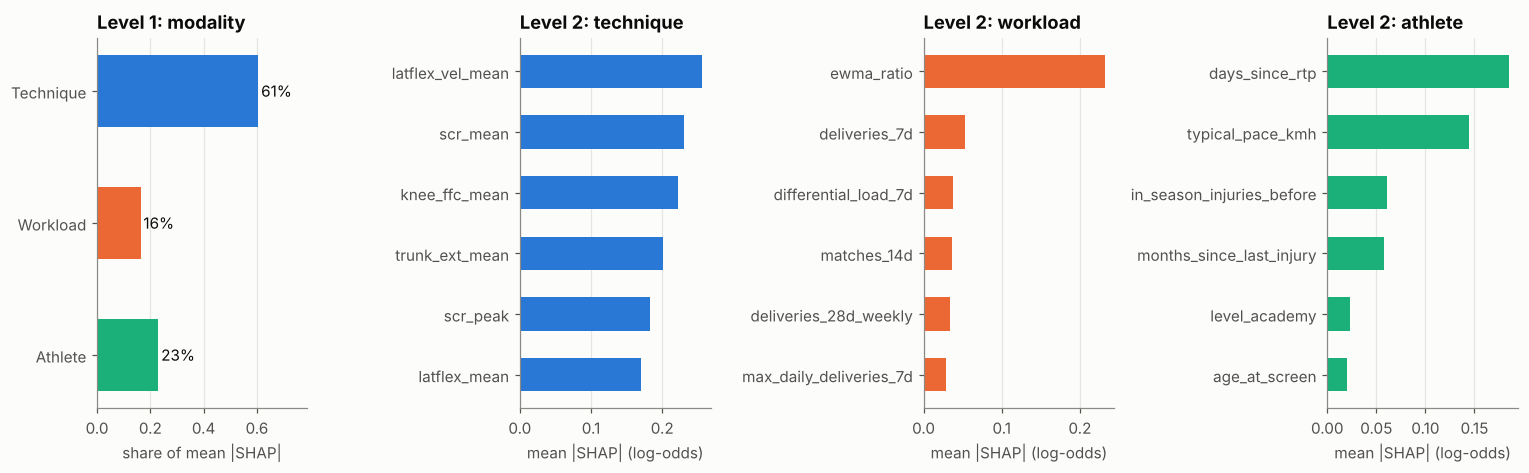

In [19]:
FEATS = list(F["X_eval"].columns)
MODALITY = {f: ("Technique" if f.startswith("lstm_") else "Workload" if f in WORK_FEATS else "Athlete") for f in FEATS}
booster, cal = F[BEST].get_booster(), final[BEST]["cal"]

def shap_calibrated(Xdf, variant=None):
    variant = variant or BEST
    b_, c_ = F[variant].get_booster(), final[variant]["cal"]
    raw = b_.predict(xgb.DMatrix(Xdf.fillna(F[variant].fill_values_)), pred_contribs=True)
    phi = raw[:, :-1] * c_.a; base = raw[0, -1] * c_.a + c_.b
    return phi, base

phi_te, base_te = shap_calibrated(F["X_eval"])
p_check = sigmoid(base_te + phi_te.sum(1))
assert np.allclose(p_check, final[BEST]["p"], atol=1e-4), "SHAP values must add up to the risk score"
mods = ["Technique", "Workload", "Athlete"]
L1 = pd.DataFrame({m: phi_te[:, [i for i, f in enumerate(FEATS) if MODALITY[f] == m]].sum(1) for m in mods})
L2 = pd.Series(np.abs(phi_te).mean(0), index=FEATS).sort_values(ascending=False)
share = L1.abs().mean() / L1.abs().mean().sum()
print("Level 1 – share of mean |SHAP| by modality:", share.round(3).to_dict())

fig = plt.figure(figsize=(14, 4.4)); gs = fig.add_gridspec(1, 4, width_ratios=[1.1, 1, 1, 1])
ax = fig.add_subplot(gs[0])
ax.barh(mods[::-1], share[mods[::-1]], color=[MOD_COLOR[m] for m in mods[::-1]], height=0.55)
for i, m in enumerate(mods[::-1]): ax.text(share[m] + 0.01, i, f"{share[m]:.0%}", va="center")
ax.set_xlim(0, max(share) * 1.3); ax.set_title("Level 1: modality"); ax.set_xlabel("share of mean |SHAP|"); ax.grid(axis="y", visible=False)
for k, m in enumerate(mods):
    ax = fig.add_subplot(gs[k + 1]); top = L2[[f for f in L2.index if MODALITY[f] == m]].head(6)[::-1]
    ax.barh([f.replace("lstm_", "") for f in top.index], top.values, color=MOD_COLOR[m], height=0.55)
    ax.set_title(f"Level 2: {m.lower()}"); ax.set_xlabel("mean |SHAP| (log-odds)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "05_two_level_shap_global.png"); plt.show()

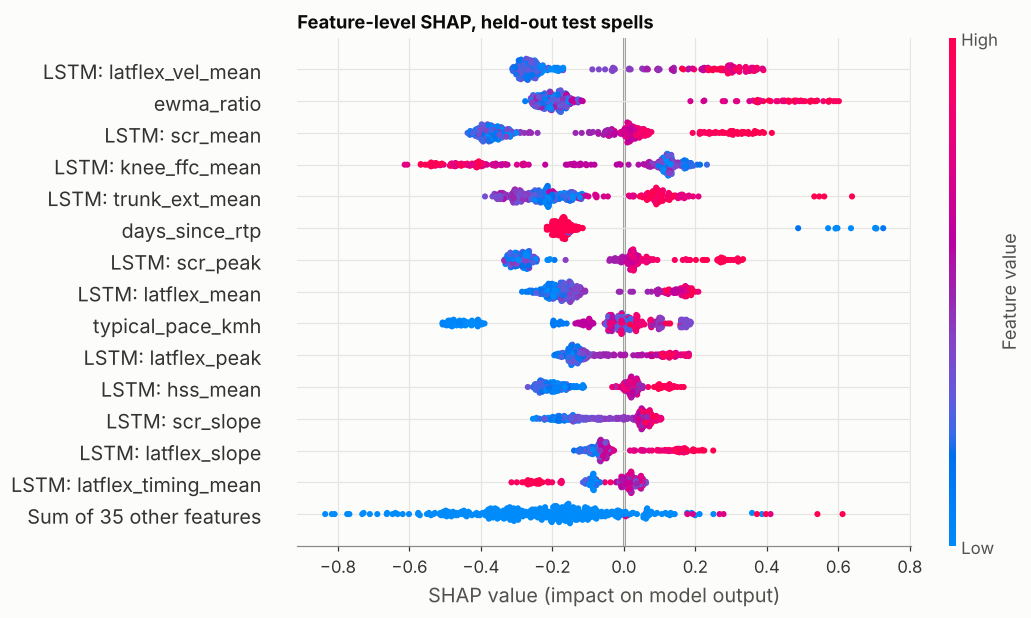

In [20]:
# Standard SHAP beeswarm (feature value colour: blue = low, red = high)
expl = shap.Explanation(values=phi_te, base_values=np.full(len(phi_te), base_te), data=F["X_eval"].values,
                        feature_names=[f.replace("lstm_", "LSTM: ") for f in FEATS])
shap.plots.beeswarm(expl, max_display=15, show=False)
plt.gcf().set_size_inches(9, 6); plt.title("Feature-level SHAP, held-out test spells", loc="left", fontweight="bold")
savefig(plt.gcf(), "06_shap_beeswarm.png"); plt.show()

### Explanation fidelity check (synthetic data only)
On synthetic data we **know** what truly drove each spell's risk (`ground_truth_spells.csv`), so we can test whether SHAP recovers it. On real data this check is replaced by the physiotherapist agreement study (target ≥ 70 %).

In [21]:
types = ["lumbar", "hamstring", "side"]
def true_groups(sp):
    # true log-odds contribution of each driver group, weighted by how much each injury type contributes to the risk
    g_ = truth.set_index("spell_id").loc[SPELL_IDS[sp]].reset_index()
    w_t = g_[[f"true_risk_28d_{t}" for t in types]].values; w_t = w_t / w_t.sum(1, keepdims=True)
    return g_, pd.DataFrame({g: (g_[[f"gt_{t}_{g}" for t in types]].values * w_t).sum(1)
                             for g in ["technique", "workload", "interaction", "host"]})
gt, G = true_groups(test_sp)
Gc = G - true_groups(dev_sp)[1].mean()        # centre on the development cohort, as SHAP is centred on its baseline
# Each bowler also has a hidden "frailty" (personal susceptibility) that no feature measures directly. The model can
# only see it through injury history, so we report the comparison with frailty excluded and with it counted as an athlete factor.
frail = gt.true_frailty.values - truth.set_index("spell_id").loc[SPELL_IDS[dev_sp]].true_frailty.mean()
risky = gt.oracle_risk_28d.values >= np.median(gt.oracle_risk_28d)
rows = []
for label, ath in [("frailty excluded", Gc.host), ("frailty counted as athlete", Gc.host + frail)]:
    Gm = pd.DataFrame({"Technique": Gc.technique + 0.5 * Gc.interaction, "Workload": Gc.workload + 0.5 * Gc.interaction, "Athlete": ath})
    tshare = Gm.abs().mean() / Gm.abs().mean().sum()
    rows.append({"ground truth": label, **{f"ρ {m}": round(spearmanr(L1[m], Gm[m]).correlation, 2) for m in mods},
                 "top-driver agreement": f"{(L1.values.argmax(1) == Gm.values.argmax(1))[risky].mean():.0%}",
                 **{f"true share {m}": round(tshare[m], 2) for m in mods}})
fidelity = pd.DataFrame(rows).set_index("ground truth")
fidelity.to_csv(f"{OUT['results']}/shap_fidelity_vs_ground_truth.csv")
Gm0 = pd.DataFrame({"Technique": Gc.technique + 0.5 * Gc.interaction, "Workload": Gc.workload + 0.5 * Gc.interaction, "Athlete": Gc.host})
perm = np.random.default_rng(SEED)
chance = np.mean([(L1.values[perm.permutation(len(L1))].argmax(1) == Gm0.values.argmax(1))[risky].mean() for _ in range(500)])
null_rank = {f: int(np.where(L2.index == f)[0][0]) + 1 for f in ["lstm_elbow_ext_mean", "years_bowling", "bowling_arm_L", "bowling_arm_R"]}
print(f"Model explained: {LABEL[BEST]}.  SHAP share by modality:", share.round(2).to_dict())
print(f"Top-driver agreement = SHAP's top modality matches the true top driver, higher-risk half of test spells "
      f"(chance level {chance:.0%}; physio-study target ≥ 70%)")
print(f"Rank of no-effect features out of {len(FEATS)} (higher = better):", null_rank)
fidelity

Model explained: Hybrid (class weights).  SHAP share by modality: {'Technique': 0.6100000143051147, 'Workload': 0.1599999964237213, 'Athlete': 0.23000000417232513}
Top-driver agreement = SHAP's top modality matches the true top driver, higher-risk half of test spells (chance level 31%; physio-study target ≥ 70%)
Rank of no-effect features out of 49 (higher = better): {'lstm_elbow_ext_mean': 18, 'years_bowling': 30, 'bowling_arm_L': 49, 'bowling_arm_R': 48}


,ρ Technique,ρ Workload,ρ Athlete,top-driver agreement,true share Technique,true share Workload,true share Athlete
ground truth,,,,,,,
frailty excluded,0.79,0.02,0.50,44%,0.57,0.24,0.19
frailty counted as athlete,0.79,0.02,0.59,44%,0.53,0.22,0.25


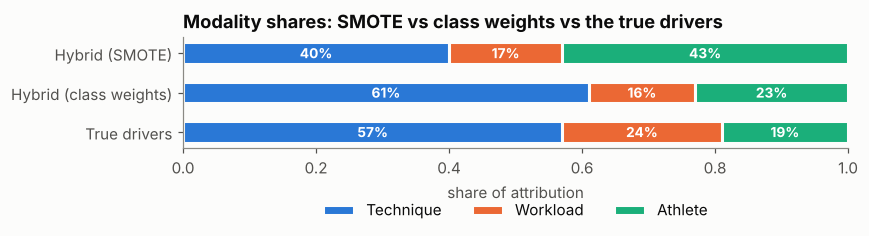

,Technique,Workload,Athlete,mean |error| vs truth
Hybrid (SMOTE),0.40,0.17,0.43,0.160
Hybrid (class weights),0.61,0.16,0.23,0.053
True drivers,0.57,0.24,0.19,0.000


In [22]:
# Does the imbalance strategy change the explanations? Compare both hybrid variants against the true driver shares.
cmp = {}
for v in ["H", "H-w"]:
    ph, _ = shap_calibrated(F["X_eval"], v)
    l1 = pd.DataFrame({m: ph[:, [i for i, f in enumerate(FEATS) if MODALITY[f] == m]].sum(1) for m in mods})
    cmp[LABEL[v]] = (l1.abs().mean() / l1.abs().mean().sum()).round(2)
cmp["True drivers"] = (Gm0.abs().mean() / Gm0.abs().mean().sum()).round(2)
cmp = pd.DataFrame(cmp).T
cmp["mean |error| vs truth"] = [round(float((cmp.loc[r, mods] - cmp.loc["True drivers", mods]).abs().mean()), 3) for r in cmp.index]
cmp.to_csv(f"{OUT['results']}/smote_vs_weights_shap_shares.csv")
fig, ax = plt.subplots(figsize=(8, 2.6))
left = np.zeros(len(cmp))
for m in mods:
    ax.barh(cmp.index[::-1], cmp[m][::-1], left=left[::-1], color=MOD_COLOR[m], height=0.55, label=m, edgecolor=C["surface"], linewidth=2)
    for k, (v, l) in enumerate(zip(cmp[m][::-1], left[::-1])):
        if v > 0.07: ax.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left = left + cmp[m].values
ax.set_xlim(0, 1); ax.set_xlabel("share of attribution"); ax.grid(False); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35))
ax.set_title("Modality shares: SMOTE vs class weights vs the true drivers")
fig.tight_layout(); savefig(fig, "06b_smote_vs_weights_shap.png"); plt.show()
cmp

## 7. Narrative explanation + data contract for Component 4
Each prediction is turned into (i) a short clinician-style narrative of the **top three factors** and (ii) a JSON record (`schema_version 1.0`) that Component 4 and the React Native screen can read without knowing anything about the model.

In [23]:
FEATURE_INFO = {  # label, unit, reference / context shown to coaches
    "lstm_scr_mean": ("Average shoulder counter-rotation", "°", "mixed-action caution level 30°"),
    "lstm_scr_peak": ("Peak shoulder counter-rotation", "°", "mixed-action caution level 30°"),
    "lstm_scr_slope": ("Change in counter-rotation per ball", "°/ball", "positive = drifting with fatigue"),
    "lstm_scr_n_over_30": ("Balls with counter-rotation over 30°", " of 12", None),
    "lstm_latflex_mean": ("Average trunk side-bend", "°", None),
    "lstm_latflex_peak": ("Peak trunk side-bend", "°", None),
    "lstm_latflex_slope": ("Increase in trunk side-bend per ball", "°/ball", "positive = fatigue drift"),
    "lstm_latflex_max_delivery": ("Ball with the largest side-bend", "", None),
    "lstm_latflex_vel_mean": ("Speed of trunk side-bend", "°/s", None),
    "lstm_hss_mean": ("Hip–shoulder separation", "°", None),
    "lstm_trunk_ext_mean": ("Back arch at front-foot landing", "°", None),
    "lstm_knee_ffc_mean": ("Front-knee bend at landing", "°", None),
    "lstm_elbow_ext_mean": ("Elbow extension", "°", None),
    "lstm_latflex_timing_mean": ("Time from landing to peak side-bend", " frames", None),
    "deliveries_7d": ("Balls bowled in the last 7 days", "", None),
    "deliveries_28d_weekly": ("Average weekly balls (last 4 weeks)", "", None),
    "acwr_7_28": ("Acute:chronic workload ratio", "", "spike zone above about 1.3"),
    "ewma_ratio": ("Workload ratio (EWMA)", "", "spike zone above about 1.3"),
    "differential_load_7d": ("Week-to-week change in balls bowled", "", None),
    "session_load_7d": ("Training load, last 7 days (sRPE×min)", " AU", None),
    "monotony_7d": ("Training monotony", "", None), "strain_7d": ("Training strain", " AU", None),
    "bowling_days_7d": ("Bowling days in the last 7 days", "", None), "matches_14d": ("Matches in the last 14 days", "", None),
    "max_daily_deliveries_7d": ("Most balls in one day (last 7 days)", "", None),
    "rest_days_7d": ("Rest days in the last 7 days", "", None), "consecutive_bowling_days": ("Consecutive bowling days", "", None),
    "age_at_screen": ("Age", " y", None), "maturity_offset_yrs": ("Years since growth spurt", " y", "lower = still maturing"),
    "typical_pace_kmh": ("Typical bowling speed", " km/h", None), "years_bowling": ("Years bowling", " y", None),
    "prior_lumbar_12m": ("Lower-back injury in last 12 months", "bool", None),
    "prior_hamstring_12m": ("Hamstring injury in last 12 months", "bool", None),
    "prior_side_strain_12m": ("Side strain in last 12 months", "bool", None),
    "prior_injury_count_12m": ("Injuries in last 12 months", "", None),
    "months_since_last_injury": ("Months since last pre-season injury", "", None),
    "in_season_injuries_before": ("Injuries earlier this season", "", None),
    "days_since_rtp": ("Days since returning from injury", "", None),
}
CAT_LABEL = {"level": "Playing level", "bowling_role": "Bowling role", "action_type_coach": "Coach-rated action", "bowling_arm": "Bowling arm"}
for f in FEATS:
    if f not in FEATURE_INFO:   # one-hot categories
        col = next(c for c in META_CAT if f.startswith(c + "_")); FEATURE_INFO[f] = (f"{CAT_LABEL[col]} is {f[len(col)+1:]}", "bool", None)
SPECIAL = {"days_since_rtp": (365.0, "no injury this season"), "months_since_last_injury": (24.0, "none in last 12 months"),
           "maturity_offset_yrs": (5.0, "adult")}   # rule-based fill values shown in plain words

ALERT_THR = final[BEST]["thr"]          # configurable: recall-weighted threshold from validation bowlers
SQUAD_AVG = float(y_all[dev_sp].mean())  # average 28-day injury rate in the development squad
HIGH_THR = min(0.95, 2 * ALERT_THR)
dev_median = F["X_train"].median()   # "squad typical" reference values

def band(p): return "high" if p >= HIGH_THR else "moderate" if p >= ALERT_THR else "low"
def fmt(f, v):
    if pd.isna(v): return "n/a"
    if f in SPECIAL and abs(float(v) - SPECIAL[f][0]) < 1e-6: return SPECIAL[f][1]
    unit = FEATURE_INFO[f][1]
    if unit == "bool": return "yes" if v >= 0.5 else "no"
    v = float(v)
    s = f"{int(round(v))}" if (v.is_integer() or abs(v) >= 10) else f"{v:.1f}" if abs(v) >= 1 else f"{v:.2f}"
    return s + unit

def explain(i_eval):
    # i_eval: row index within the test set -> JSON record
    sid = SPELL_IDS[test_sp][i_eval]; p = float(final[BEST]["p"][i_eval]); phi = phi_te[i_eval]; x = F["X_eval"].iloc[i_eval]
    order_ = np.argsort(-np.abs(phi))
    factors = [dict(rank=r + 1, feature=FEATS[j], label=FEATURE_INFO[FEATS[j]][0], modality=MODALITY[FEATS[j]],
                    value=None if pd.isna(x.iloc[j]) else round(float(x.iloc[j]), 3), display_value=fmt(FEATS[j], x.iloc[j]),
                    cohort_median=round(float(dev_median[FEATS[j]]), 3), reference=FEATURE_INFO[FEATS[j]][2],
                    direction="increases_risk" if phi[j] > 0 else "decreases_risk", shap_logodds=round(float(phi[j]), 4))
               for r, j in enumerate(order_)]
    lvl1 = {m: float(phi[[k for k, f in enumerate(FEATS) if MODALITY[f] == m]].sum()) for m in mods}
    up = {m: max(0.0, v) for m, v in lvl1.items()}; tot = sum(up.values())
    alert = p >= ALERT_THR
    # alerted spell -> the three factors that raised risk most; otherwise -> the three largest factors either way
    raising = [fc for fc in factors if fc["direction"] == "increases_risk"]
    top3 = (raising[:3] if alert and raising else factors[:3])
    lines = [f"Estimated risk of a time-loss injury in the next 4 weeks: {p:.0%}. {band(p).upper()}"
             + (f" (alert threshold {ALERT_THR:.0%}; squad average {SQUAD_AVG:.0%})." )]
    lines.append("Main reasons for the raised risk:" if alert else "Main factors:")
    for r, fct in enumerate(top3, 1):
        med = fmt(fct["feature"], fct["cohort_median"])
        ctx = f"squad typical {med}" + (f"; {fct['reference']}" if fct["reference"] else "")
        verb = "raised" if fct["direction"] == "increases_risk" else "lowered"
        lines.append(f"  {r}. {fct['label']}: {fct['display_value']} ({ctx}). This {verb} the risk.")
    if tot > 0:
        lines.append("Share of the upward push: " + ", ".join(f"{m.lower()} {up[m]/tot:.0%}" for m in mods) + ".")
    else:
        lines.append("No factor group pushed the risk above the squad average"
                     + (" — the alert is set low on purpose so that at least 80% of injuries are caught." if alert else "."))
    lines.append("Decision support only, not a diagnosis. Review with the coach or physiotherapist.")
    tot = tot or 1.0
    return dict(schema_version="1.0", model_version=f"cricshield-c3-{BEST}-0.1-synthetic", synthetic_data=True,
                spell_id=sid, bowler_id=spells.bowler_id[test_sp[i_eval]], screen_date=spells.screen_date[test_sp[i_eval]],
                risk=dict(probability=round(p, 4), percent=round(100 * p, 1), band=band(p), alert=bool(p >= ALERT_THR),
                          alert_threshold=round(ALERT_THR, 4), horizon_days=HORIZON_DAYS),
                modality_attribution=[dict(modality=m, shap_logodds=round(lvl1[m], 4), share_of_upward_push=round(up[m] / tot, 3)) for m in mods],
                top_factors=top3, all_factors=factors, narrative="\n".join(lines))

# three example spells: highest risk, one near the threshold, one low
p_te = final[BEST]["p"]
examples = {"high": int(np.argmax(p_te)), "moderate": int(np.argmin(np.abs(p_te - (ALERT_THR + HIGH_THR) / 2))), "low": int(np.argmin(p_te))}
for name, i in examples.items():
    rec = explain(i)
    with open(f"{OUT['examples']}/explanation_{name}.json", "w") as fh: json.dump(rec, fh, indent=2)
    print(f"── {name.upper()} example: {rec['spell_id']} (injury in next 28 d: {'yes' if y_te[i] else 'no'}) ──")
    print(rec["narrative"], "\n")

── HIGH example: CS092-W18 (injury in next 28 d: yes) ──
Estimated risk of a time-loss injury in the next 4 weeks: 58%. HIGH (alert threshold 6%; squad average 8%).
Main reasons for the raised risk:
  1. Days since returning from injury: 4 (squad typical no injury this season). This raised the risk.
  2. Workload ratio (EWMA): 3.0 (squad typical 1.1; spike zone above about 1.3). This raised the risk.
  3. Average shoulder counter-rotation: 47° (squad typical 29°; mixed-action caution level 30°). This raised the risk.
Share of the upward push: technique 36%, workload 26%, athlete 38%.
Decision support only, not a diagnosis. Review with the coach or physiotherapist. 

── MODERATE example: CS069-W14 (injury in next 28 d: no) ──
Estimated risk of a time-loss injury in the next 4 weeks: 9%. MODERATE (alert threshold 6%; squad average 8%).
Main reasons for the raised risk:
  1. Average shoulder counter-rotation: 43° (squad typical 29°; mixed-action caution level 30°). This raised the risk.
 

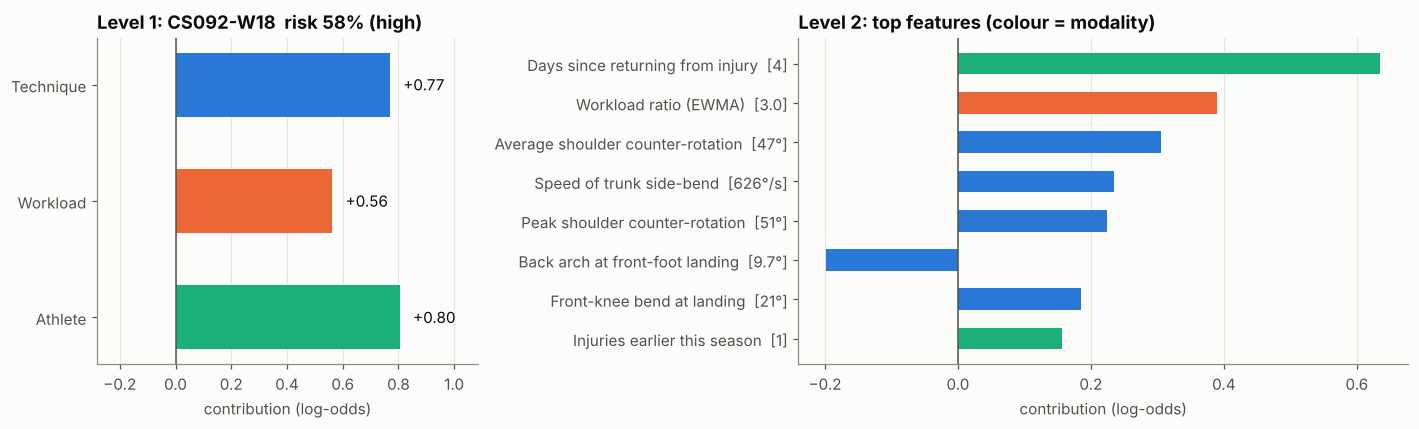

In [24]:
# Per-spell view for the high-risk example: Level 1 + Level 2 together
i = examples["high"]; rec = explain(i); phi = phi_te[i]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1, 1.6]))
ax = axes[0]; lv = [a["shap_logodds"] for a in rec["modality_attribution"]]
ax.barh(mods[::-1], lv[::-1], color=[MOD_COLOR[m] for m in mods[::-1]], height=0.55); ax.axvline(0, color=C["ink2"], lw=1)
span = max(lv) - min(0, min(lv)); pad = 0.06 * span
ax.set_xlim(min(0, min(lv)) - 0.35 * span, max(0, max(lv)) + 0.35 * span)
for k, v in enumerate(lv[::-1]): ax.text(v + (pad if v >= 0 else -pad), k, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right")
ax.set_title(f"Level 1: {rec['spell_id']}  risk {rec['risk']['percent']:.0f}% ({rec['risk']['band']})"); ax.set_xlabel("contribution (log-odds)"); ax.grid(axis="y", visible=False)
ax = axes[1]; top = rec["all_factors"][:8][::-1]
ax.barh([f"{t['label']}  [{t['display_value']}]" for t in top], [t["shap_logodds"] for t in top],
        color=[MOD_COLOR[t["modality"]] for t in top], height=0.55); ax.axvline(0, color=C["ink2"], lw=1)
ax.set_title("Level 2: top features (colour = modality)"); ax.set_xlabel("contribution (log-odds)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "07_example_spell_explanation.png"); plt.show()

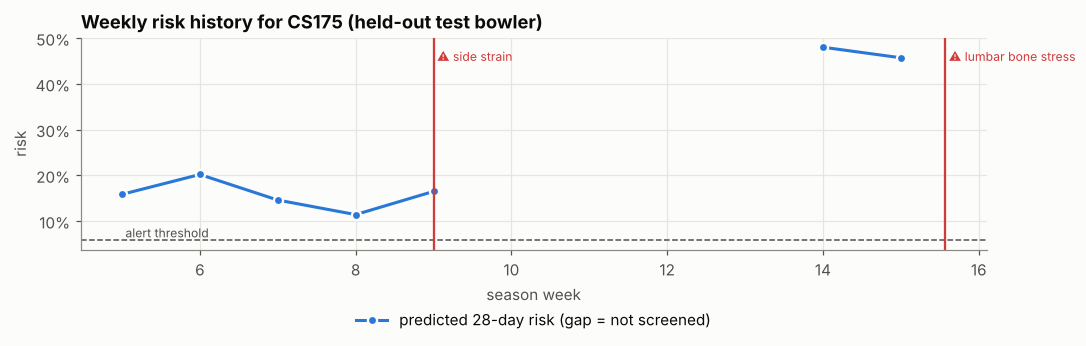

In [25]:
# Risk history for one test bowler (functional requirement: longitudinal trend review)
hist = spells.iloc[test_sp][["spell_id", "bowler_id", "screen_date", "season_week"]].copy()
hist["risk"] = p_te; hist["alert"] = p_te >= ALERT_THR; hist["injury_28d"] = y_te
hist.to_csv(f"{OUT['results']}/test_risk_history.csv", index=False)
b = hist.groupby("bowler_id").injury_28d.sum().idxmax(); h = hist[hist.bowler_id == b]
inj_b = injuries[injuries.bowler_id == b]
fig, ax = plt.subplots(figsize=(10, 3.4))
hw = h.set_index("season_week").risk.reindex(range(h.season_week.min(), h.season_week.max() + 1))   # gaps = not screened (injured)
ax.plot(hw.index, hw.values, "o-", color=C["blue"], ms=6, mec=C["surface"], mew=1.5, label="predicted 28-day risk (gap = not screened)")
ax.axhline(ALERT_THR, color=C["ink2"], lw=1, ls="--"); ax.text(h.season_week.min(), ALERT_THR, " alert threshold", va="bottom", color=C["ink2"], fontsize=8)
for _, r in inj_b.iterrows():
    wk = r.onset_day / 7 + 1
    ax.axvline(wk, color=C["critical"], lw=1.5); ax.text(wk, ax.get_ylim()[1] * 0.95, f" ⚠ {r.injury_type.replace('_', ' ')}", color=C["critical"], fontsize=8, va="top")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_xlabel("season week"); ax.set_ylabel("risk")
ax.set_title(f"Weekly risk history for {b} (held-out test bowler)"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout(); savefig(fig, "08_risk_history_example.png"); plt.show()

## 8. Level 0 (optional): where in the delivery did the LSTM look?
Integrated gradients on the concept encoder show which frames drove the *shoulder counter-rotation* concept. If the bridge is sound, attribution should concentrate between back-foot and front-foot contact, where counter-rotation is defined.

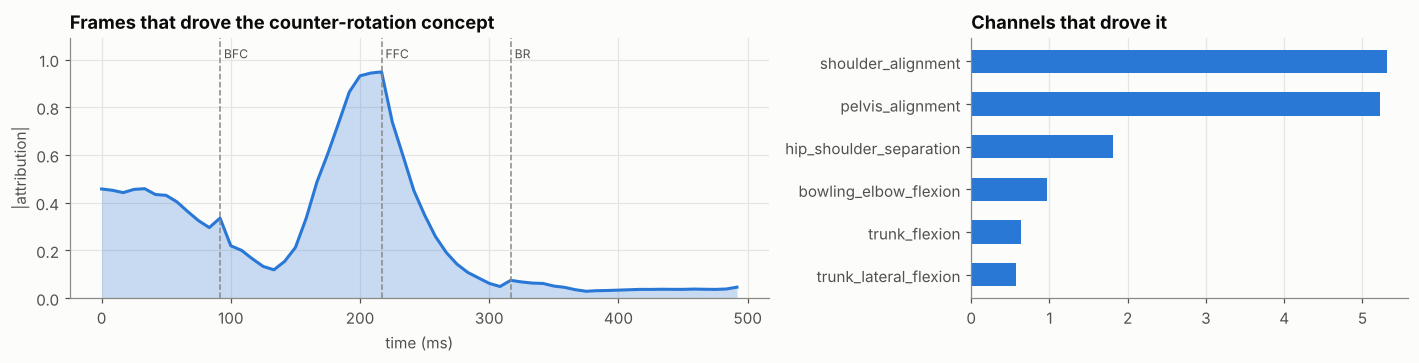

In [26]:
enc = F["encoder"]
def integrated_gradients(x, concept_idx, steps=48):
    x = tf.convert_to_tensor(x[None], tf.float32); base = tf.zeros_like(x)
    alphas = tf.reshape(tf.linspace(0.0, 1.0, steps + 1), (-1, 1, 1, 1))
    path = base + alphas * (x - base)
    with tf.GradientTape() as tape:
        tape.watch(path); out = enc["model"](tf.reshape(path, (-1, T, N_IN)))[:, concept_idx]
    g = tape.gradient(out, path)
    return ((x - base) * tf.reduce_mean((g[:-1] + g[1:]) / 2, axis=0)).numpy()[0]

d = int(D_IDX[test_sp[examples["high"]]][-1])
ig = np.abs(integrated_gradients(enc["sx"](X_in[d:d + 1])[0], CN.index("scr")))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]; frame_imp = ig.sum(1)
ax.fill_between(t_ms, frame_imp, color=C["blue"], alpha=0.25, lw=0); ax.plot(t_ms, frame_imp, color=C["blue"])
ax.set_ylim(0, frame_imp.max() * 1.15)
for ev, lab in [("bfc_frame", "BFC"), ("ffc_frame", "FFC"), ("br_frame", "BR")]:
    f = deliv.loc[d, ev] / FPS * 1000; ax.axvline(f, color=C["muted"], lw=1, ls="--"); ax.text(f + 3, frame_imp.max() * 1.08, lab, ha="left", va="center", fontsize=8, color=C["ink2"])
ax.set_xlabel("time (ms)"); ax.set_ylabel("|attribution|"); ax.set_title("Frames that drove the counter-rotation concept")
ax = axes[1]; ch_names = [c.replace("_deg", "") for c in CHANNELS] + ["ev_BFC", "ev_FFC", "ev_UAH", "ev_BR"]
ci = pd.Series(ig.sum(0), index=ch_names).sort_values().tail(6)
ax.barh(ci.index, ci.values, color=C["blue"], height=0.55); ax.set_title("Channels that drove it"); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "09_level0_integrated_gradients.png"); plt.show()

## 9. Inference speed and saving the model

In [27]:
# Non-functional requirement: risk score + narrative within 5 s of receiving a complete record
def predict_one(spell_pos):
    d_idx = D_IDX[spell_pos]
    Cd = enc["model"](enc["sx"](X_in[d_idx]), training=False).numpy() * enc["ysd"] + enc["ymu"]
    x = pd.concat([spell_concept_features(Cd[None]), tabular([spell_pos])], axis=1)[FEATS]
    raw = booster.predict(xgb.DMatrix(x.fillna(F[BEST].fill_values_)), pred_contribs=True)
    return float(sigmoid((raw[0, :-1] * cal.a).sum() + raw[0, -1] * cal.a + cal.b))
_ = predict_one(test_sp[0])
t0 = time.perf_counter(); n = 20
for s in test_sp[:n]: predict_one(s)
lat = (time.perf_counter() - t0) / n
print(f"end-to-end inference per spell (12 deliveries → risk + SHAP): {lat * 1000:.0f} ms  (requirement: < 5000 ms)")

end-to-end inference per spell (12 deliveries → risk + SHAP): 469 ms  (requirement: < 5000 ms)


In [28]:
enc["model"].save(f"{OUT['models']}/concept_encoder.keras")
F[BEST].save_model(f"{OUT['models']}/xgb_hybrid.json")
bundle = dict(
    schema_version="1.0", synthetic_data=True, created=time.strftime("%Y-%m-%d %H:%M"),
    channels=CHANNELS, event_channels=EVENTS, frames=T, fps=FPS, deliveries_per_spell=N_DEL,
    seq_scaler=dict(mu=enc["sx"].mu.tolist(), sd=enc["sx"].sd.tolist()),
    concepts=CONCEPTS, concept_scaler=dict(mu=enc["ymu"].tolist(), sd=enc["ysd"].tolist()),
    features=FEATS, modality=MODALITY, fill_values=F[BEST].fill_values_.to_dict(),
    metadata_fill_rules=dict(maturity_offset_yrs=5.0, months_since_last_injury=24.0, days_since_rtp=365.0),
    platt=dict(a=cal.a, b=cal.b), alert_threshold=ALERT_THR, high_threshold=HIGH_THR, target_recall=TARGET_RECALL,
    selected_variant=LABEL[BEST], cv_auc_mean=float(cv_summary.loc[BEST, ("AUC", "mean")]), test_auc=float(roc_auc_score(y_te, p_te)),
)
with open(f"{OUT['models']}/preprocessing_and_calibration.json", "w") as fh: json.dump(bundle, fh, indent=2)
pd.DataFrame({"feature": FEATS, "modality": [MODALITY[f] for f in FEATS], "mean_abs_shap_test": L2[FEATS].values}).sort_values(
    "mean_abs_shap_test", ascending=False).to_csv(f"{OUT['results']}/shap_feature_importance_test.csv", index=False)
print("saved:", sorted(os.listdir(OUT["models"])))

saved: ['concept_encoder.keras', 'preprocessing_and_calibration.json', 'xgb_hybrid.json']


In [29]:
# Zip everything (download it from Colab, or it is already in Drive if you used Option B)
import shutil
zip_path = shutil.make_archive(os.path.join(os.path.dirname(os.path.abspath(OUT_ROOT)), "cricshield_c3_outputs"), "zip", OUT_ROOT)
print("outputs zipped to", zip_path)
if IN_COLAB and not OUT_ROOT.startswith("/content/drive"):
    from google.colab import files; files.download(zip_path)

outputs zipped to /home/claude/cricshield_nb/cricshield_c3_outputs.zip


## 10. What to say about these results (PP1)
* **What this shows:** the full Component 3 pipeline runs end to end. The LSTM bridge reproduces Component 2's metrics on unseen bowlers, the fused model beats every single-modality baseline under bowler-grouped CV, SHAP recovers the known risk drivers, and each prediction comes with a narrative and a JSON record for Component 4 in well under 5 s.
* **What it does not show:** real-world accuracy. The data is synthetic, and the hybrid's advantage was designed into the generator. Real performance will be measured on primary data.
* **Report CV numbers as the headline.** The held-out test set has only 29 bowlers, so its confidence intervals are wide.
* **Next:** swap the loading cell for real Component 1/2 output and the coach workload log, then run the physiotherapist SHAP-agreement study (target ≥ 70 %).